In [1]:
# Cell 1: setup and paths
# If an import fails on SOL, run once:  !pip install --user pandas numpy matplotlib
import os, sys, textwrap
from datetime import datetime, timedelta
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, display
%matplotlib inline

BASE = os.path.expanduser("~/ev_metrics")      # change if you want another folder
DATA = os.path.join(BASE, "sample_data")
OUT  = os.path.join(BASE, "results")
os.makedirs(DATA, exist_ok=True)
os.makedirs(OUT, exist_ok=True)

# input files (point these at the real load generator output later)
OUTCOMES = os.path.join(DATA, "outcomes.csv")
PORTS_PATH = os.path.join(DATA, "ports.csv")    # optional
RIGHTS   = os.path.join(DATA, "rights_log.csv")  # optional, for the one-booking-city check
FAULTS   = os.path.join(DATA, "faults.csv")      # optional
print("working in", BASE)

working in /home/budayaku/ev_metrics


In [2]:
# Cell 2: settings for the fake data (from the Phase 2 design)
CITIES = [1, 2, 3]
PORTS = {1: 310, 2: 200, 3: 112}            # initial static split (Phase 2, 2.2)
DEMAND_SHARE = {1: 0.76, 2: 0.23, 3: 0.01}  # synthetic driver split (Phase 2, 2.2)
NEIGHBORS = {1: [2, 3], 2: [1, 3], 3: [2, 1]}  # ordered by distance
LEND_TRIGGER = 0.10   # borrower asks when idle owned ports < 10 percent
LEND_FRACTION = 0.20  # lender gives 20 percent of its surplus
LEND_RESERVE = 0.10   # lender always keeps 10 percent of its ports idle

START = datetime(2026, 11, 2, 0, 0, 0)
DAYS = 3
REQ_PER_DAY = 2600

# fault windows (day 2, 10:00 to 12:00)
FAULT_START = START + timedelta(days=1, hours=10)
FAULT_END = START + timedelta(days=1, hours=12)
CRASH_CITY = 2

In [3]:
# Cell 3: tiny simulation of both methods
def make_requests(rng):
    """Same trace for every run: arrival time, home city, slot."""
    hours = np.arange(24)
    # daytime-heavy arrival profile
    profile = np.exp(-0.5 * ((hours - 13) / 3.5) ** 2) + 0.05
    profile = profile / profile.sum()
    rows = []
    rid = 0
    for d in range(DAYS):
        n = rng.poisson(REQ_PER_DAY)
        hrs = rng.choice(hours, size=n, p=profile)
        mins = rng.uniform(0, 60, size=n)
        homes = rng.choice(CITIES, size=n, p=[DEMAND_SHARE[c] for c in CITIES])
        lead = rng.uniform(0, 10, size=n)                        # book up to 10 min ahead
        dur = np.clip(rng.lognormal(np.log(150), 0.45, size=n), 30, 480)  # minutes
        for h, m, c, l, du in zip(hrs, mins, homes, lead, dur):
            t = START + timedelta(days=d, hours=int(h), minutes=float(m))
            s = t + timedelta(minutes=float(l))
            rows.append((t, int(c), s, s + timedelta(minutes=float(du))))
    rows.sort(key=lambda r: r[0])
    out = []
    for r in rows:
        rid += 1
        out.append({"request_id": f"R{rid:06d}", "request_time": r[0], "home_city": r[1],
                    "slot_start": r[2], "slot_end": r[3]})
    return pd.DataFrame(out)


def run(trace, method, scenario, seed):
    rng = np.random.default_rng(seed)
    port_ids = np.array([f"C{c}-P{i:03d}" for c in CITIES for i in range(PORTS[c])])
    initial = np.array([c for c in CITIES for _ in range(PORTS[c])])
    booking_city = initial.copy()                      # who may book now
    busy_until = np.zeros(len(port_ids))               # minutes since START
    rights = [{"port_id": p, "city": int(c), "valid_from": START, "valid_to": None}
              for p, c in zip(port_ids, initial)]
    rights_open = list(range(len(port_ids)))

    def mins(t):
        return (t - START).total_seconds() / 60.0

    def city_up(c, t):
        return not (scenario == "crash" and c == CRASH_CITY and FAULT_START <= t < FAULT_END)

    def linked(t):
        return not (scenario == "partition" and FAULT_START <= t < FAULT_END)

    def in_fault(t):
        return scenario in ("crash", "partition") and FAULT_START <= t < FAULT_END

    def free_idx(c, at, by_initial=False):
        key = initial if by_initial else booking_city
        return np.flatnonzero((key == c) & (busy_until <= at))

    def transfer(lender, borrower, n, t, at):
        idx = free_idx(lender, at)[:n]
        for k in idx:
            # lender gives up the right, port is 'in transit' (nobody may book) for 500 ms,
            # then the borrower's right starts; the transfer completes before the borrower books
            rights[rights_open[k]]["valid_to"] = t - timedelta(milliseconds=500)
            rights.append({"port_id": port_ids[k], "city": borrower,
                           "valid_from": t, "valid_to": None})
            rights_open[k] = len(rights) - 1
            booking_city[k] = borrower
        return len(idx)

    crash_wiped = False
    active_row = {}                      # port index -> row of its latest reservation
    out = []
    for r in trace.itertuples(index=False):
        t, home, s, e = r.request_time, r.home_city, r.slot_start, r.slot_end
        sm, em = mins(s), mins(e)

        # crash with storage wipe: reservations held at the crashed city are lost
        if scenario == "crash" and not crash_wiped and t >= FAULT_START:
            fm = mins(FAULT_START)
            for k in np.flatnonzero((booking_city == CRASH_CITY) & (busy_until > fm)):
                if k in active_row:
                    out[active_row[k]]["lost_in_crash"] = 1
            busy_until[booking_city == CRASH_CITY] = 0.0
            crash_wiped = True

        # flags measured by the harness at decision time
        home_overflow = int(len(free_idx(home, sm, by_initial=True)) == 0)
        free_anywhere = int(any(city_up(c, t) and len(free_idx(c, sm)) for c in CITIES))

        # dynamic escrow: lending manager tops up a city that is running low
        borrowed_now = False
        if method == "dynamic" and city_up(home, t) and linked(t):
            owned = int((booking_city == home).sum())
            idle = len(free_idx(home, sm))
            if idle < LEND_TRIGGER * max(owned, 1):
                cands = []
                for nb in NEIGHBORS[home]:
                    if city_up(nb, t):
                        nb_owned = int((booking_city == nb).sum())
                        surplus = len(free_idx(nb, sm)) - int(LEND_RESERVE * nb_owned)
                        if surplus > 0:
                            cands.append((surplus, nb))
                if cands:
                    surplus, lender = max(cands)
                    n = max(1, int(LEND_FRACTION * surplus))
                    if transfer(lender, home, n, t, sm) and idle == 0:
                        borrowed_now = True

        outcome, served, port, path, reason = "rejected", "", "", "", "no_port"
        entry = home
        if not city_up(home, t):
            # load generator fails over to the next closest city
            entry = next((nb for nb in NEIGHBORS[home] if city_up(nb, t)), None)
            if entry is None or not linked(t):
                reason, entry = "unreachable", None
        k = None
        if entry is not None:
            fi = free_idx(entry, sm)
            if len(fi):
                k, served = fi[0], entry
                if entry != home:
                    path = "redirect"
                else:
                    path = "borrowed" if initial[k] != home else "local"
            elif entry == home:
                nb = NEIGHBORS[home][0]          # one redirect, nearest neighbor only
                if not city_up(nb, t) or not linked(t):
                    reason = "unreachable"
                else:
                    fi = free_idx(nb, sm)
                    if len(fi):
                        k, served, path = fi[0], nb, "redirect"
        if k is not None:
            busy_until[k] = em
            active_row[k] = len(out)
            port = port_ids[k]
            outcome, reason = "accepted", ""

        latency = float(rng.lognormal(np.log(12 if path in ("local", "borrowed", "") else 35), 0.3))
        out.append({
            "run_id": f"{scenario}-{method}", "method": method, "scenario": scenario,
            "request_id": r.request_id, "request_time": t, "home_city": home,
            "slot_start": s, "slot_end": e, "outcome": outcome,
            "served_city": served, "port_id": port, "path": path, "reject_reason": reason,
            "latency_ms": round(latency, 1), "during_fault": int(in_fault(t)),
            "home_overflow": home_overflow, "free_port_anywhere": free_anywhere,
            "lost_in_crash": 0, "synthetic": 1,
        })
    rl = pd.DataFrame(rights)
    rl.insert(0, "run_id", f"{scenario}-{method}")
    return pd.DataFrame(out), rl

In [4]:
# Cell 4: generate the fake outcome log (takes a few seconds)
SEED = 7
rng = np.random.default_rng(SEED)
trace = make_requests(rng)
outs, rls = [], []
for scenario in ["normal", "crash", "partition"]:
    for method in ["static", "dynamic"]:
        o, rl = run(trace, method, scenario, SEED)
        outs.append(o); rls.append(rl)
        print(f"{scenario:9s} {method:7s} requests={len(o)} accepted={int((o.outcome=='accepted').sum())}")
pd.concat(outs, ignore_index=True).to_csv(OUTCOMES, index=False)
pd.concat(rls, ignore_index=True).to_csv(RIGHTS, index=False)
pd.DataFrame([{"port_id": f"C{c}-P{i:03d}", "initial_city": c}
              for c in CITIES for i in range(PORTS[c])]).to_csv(PORTS_PATH, index=False)
pd.DataFrame([
    {"scenario": "crash", "fault_type": "node_crash", "city": CRASH_CITY, "start": FAULT_START, "end": FAULT_END},
    {"scenario": "partition", "fault_type": "network_partition", "city": "", "start": FAULT_START, "end": FAULT_END},
]).to_csv(FAULTS, index=False)
print("wrote", OUTCOMES)

normal    static  requests=7838 accepted=6763
normal    dynamic requests=7838 accepted=7436
crash     static  requests=7838 accepted=6712
crash     dynamic requests=7838 accepted=7438
partition static  requests=7838 accepted=6756
partition dynamic requests=7838 accepted=7436
wrote /home/budayaku/ev_metrics/sample_data/outcomes.csv


/tmp/ipykernel_4149867/1485540109.py:12: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  pd.concat(rls, ignore_index=True).to_csv(RIGHTS, index=False)


In [5]:
# Cell 5: constants and loading the outcome log
REQUIRED = ["method", "scenario", "request_id", "request_time", "home_city",
            "slot_start", "slot_end", "outcome", "served_city", "port_id"]
TIME_COLS = ["request_time", "slot_start", "slot_end"]

METHOD_ORDER = ["static", "dynamic"]
METHOD_LABEL = {"static": "Static escrow (Method 2)", "dynamic": "Dynamic escrow (Method 1)"}
METHOD_COLOR = {"static": "#2a78d6", "dynamic": "#eb6834"}   # validated pair
SCENARIO_ORDER = ["normal", "crash", "partition", "transfer_crash"]
SCENARIO_LABEL = {"normal": "Normal", "crash": "Node crash", "partition": "Network partition",
                  "transfer_crash": "Crash during transfer"}
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"


# ---------------------------------------------------------------- loading
def load_outcomes(path):
    df = pd.read_csv(path)
    missing = [c for c in REQUIRED if c not in df.columns]
    if missing:
        raise ValueError(f"outcomes file is missing required columns: {missing}")
    for c in TIME_COLS:
        df[c] = pd.to_datetime(df[c])
    df["method"] = df["method"].str.strip().str.lower()
    df["scenario"] = df["scenario"].str.strip().str.lower()
    df["outcome"] = df["outcome"].str.strip().str.lower()
    bad = set(df["outcome"]) - {"accepted", "rejected"}
    if bad:
        raise ValueError(f"outcome must be 'accepted' or 'rejected', found: {bad}")
    if "run_id" not in df.columns:
        df["run_id"] = df["scenario"] + "-" + df["method"]
    df["accepted"] = df["outcome"].eq("accepted")
    df["lost_in_crash"] = df["lost_in_crash"].fillna(0).astype(int) if "lost_in_crash" in df.columns else 0
    return df


def add_fault_flag(df, faults_path):
    """during_fault = request_time falls inside an injected fault window for that scenario."""
    if "during_fault" in df.columns:
        df["during_fault"] = df["during_fault"].fillna(0).astype(int)
        return df, "logged"
    df["during_fault"] = 0
    if not faults_path:
        return df, "not available (no during_fault column and no --faults file)"
    f = pd.read_csv(faults_path, parse_dates=["start", "end"])
    for row in f.itertuples(index=False):
        m = df["scenario"].eq(str(row.scenario).lower()) & \
            df["request_time"].ge(row.start) & df["request_time"].lt(row.end)
        df.loc[m, "during_fault"] = 1
    return df, "derived from faults file"


def add_capacity_flags(df, ports_path):
    """
    Fallback when the log does not have home_overflow / free_port_anywhere.
    Rebuilds port occupancy from the accepted reservations, in request order:
      home_overflow       home city had no free port among the ports it owned under
                          the initial static split, during the requested slot
      free_port_anywhere  some port in any city was free during the requested slot
    It ignores fault windows (a crashed city's ports count as free), so prefer
    logging both flags from the load generator.
    """
    have = {"home_overflow", "free_port_anywhere"} <= set(df.columns)
    if have:
        return df, "logged"
    if not ports_path:
        raise ValueError("outcomes has no home_overflow / free_port_anywhere columns; set PORTS_PATH so they can be derived")
    ports = pd.read_csv(ports_path)
    owner = dict(zip(ports["port_id"], ports["initial_city"]))
    n_owned = ports["initial_city"].value_counts().to_dict()
    n_total = len(ports)
    parts = []
    for _, g in df.sort_values("request_time").groupby("run_id", sort=False):
        acc = g[g["accepted"]]
        r_t = acc["request_time"].values
        r_s = acc["slot_start"].values
        r_e = acc["slot_end"].values
        r_c = acc["port_id"].map(owner).values
        r_p = acc["port_id"].values
        ovf, anyfree = [], []
        for t, home, s, e in zip(g["request_time"].values, g["home_city"].values,
                                 g["slot_start"].values, g["slot_end"].values):
            # a port is taken if a reservation committed earlier overlaps the requested slot
            active = (r_t < t) & (r_s < e) & (r_e > s)
            # count distinct busy ports, not reservations (one port can hold two short bookings)
            busy_home = len(np.unique(r_p[active & (r_c == home)]))
            ovf.append(int(busy_home >= n_owned.get(home, 0)))
            anyfree.append(int(len(np.unique(r_p[active])) < n_total))
        g = g.copy()
        g["home_overflow"] = ovf
        g["free_port_anywhere"] = anyfree
        parts.append(g)
    return pd.concat(parts).sort_index(), "derived from ports file (approximate)"

In [6]:
# Cell 6: correctness checks (double booking D, one booking city per port)
def double_booking(df):
    """
    D: overlapping pairs of committed reservations on the same port, per run.
    Reservations wiped in a node crash (lost_in_crash = 1) are no longer committed,
    so they are left out here and reported separately as lost data.
    """
    rows = []
    acc = df[df["accepted"] & df["lost_in_crash"].eq(0)].dropna(subset=["port_id"])
    for (run, port), g in acc.groupby(["run_id", "port_id"]):
        if len(g) < 2:
            continue
        g = g.sort_values("slot_start")
        s = g["slot_start"].values
        e = g["slot_end"].values
        ids = g["request_id"].values
        for i in range(len(g)):
            j = i + 1
            while j < len(g) and s[j] < e[i]:     # slot(a) and slot(b) intersect
                rows.append({"run_id": run, "port_id": port,
                             "request_a": ids[i], "request_b": ids[j],
                             "slot_a": f"{s[i]} to {e[i]}", "slot_b": f"{s[j]} to {e[j]}"})
                j += 1
    return pd.DataFrame(rows, columns=["run_id", "port_id", "request_a", "request_b", "slot_a", "slot_b"])


def booking_authority(df, rights_path):
    """
    At every time t each port has at most one city allowed to book it, and every
    accepted reservation was made by the city that held the right at that moment.
    rights_log columns: run_id, port_id, city, valid_from, valid_to (blank = still valid)
    """
    cols = ["run_id", "port_id", "problem", "detail"]
    if not rights_path:
        return None
    r = pd.read_csv(rights_path, parse_dates=["valid_from", "valid_to"])
    r["valid_to"] = r["valid_to"].fillna(pd.Timestamp.max)
    out = []
    for (run, port), g in r.groupby(["run_id", "port_id"]):
        g = g.sort_values("valid_from")
        f, t, c = g["valid_from"].values, g["valid_to"].values, g["city"].values
        for i in range(1, len(g)):
            if f[i] < t[i - 1] and c[i] != c[i - 1]:
                out.append({"run_id": run, "port_id": port, "problem": "two cities could book",
                            "detail": f"city {c[i-1]} and city {c[i]} overlap at {f[i]}"})
    # every accepted booking must come from the city holding the right
    acc = df[df["accepted"] & df["lost_in_crash"].eq(0)][["run_id", "port_id", "served_city", "request_time", "request_id"]]
    m = acc.merge(r, on=["run_id", "port_id"], how="left")
    m["holds"] = (m["valid_from"] <= m["request_time"]) & (m["request_time"] < m["valid_to"]) & \
                 (m["city"].astype(str) == m["served_city"].astype(str).str.replace(".0", "", regex=False))
    ok = m.groupby(["run_id", "request_id"])["holds"].any()
    for (run, rid) in ok[~ok].index:
        port = acc.loc[(acc["run_id"] == run) & (acc["request_id"] == rid), "port_id"].iloc[0]
        out.append({"run_id": run, "port_id": port, "problem": "booked without the right",
                    "detail": f"request {rid}"})
    return pd.DataFrame(out, columns=cols)

In [7]:
# Cell 7: OAR, SRR, AuF per run
def rate(num, den):
    return np.nan if den == 0 else num / den


def compute_summary(df, db, auth):
    rows = []
    for (run, scen, meth), g in df.groupby(["run_id", "scenario", "method"]):
        ovf = g[g["home_overflow"] == 1]
        stranded = g[(~g["accepted"]) & (g["free_port_anywhere"] == 1)]
        fault = g[g["during_fault"] == 1]
        lat = g["latency_ms"] if "latency_ms" in g.columns else pd.Series(dtype=float)
        d = int((db["run_id"] == run).sum()) if len(db) else 0
        a = None if auth is None else int((auth["run_id"] == run).sum())
        rows.append({
            "run_id": run, "scenario": scen, "method": meth,
            "requests": len(g), "accepted": int(g["accepted"].sum()),
            "acceptance_rate": rate(g["accepted"].sum(), len(g)),
            "overflow_requests": len(ovf), "overflow_accepted": int(ovf["accepted"].sum()),
            "OAR": rate(ovf["accepted"].sum(), len(ovf)),
            "stranded_rejections": len(stranded),
            "SRR": rate(len(stranded), len(g)),
            "fault_requests": len(fault), "fault_accepted": int(fault["accepted"].sum()),
            "AuF": rate(fault["accepted"].sum(), len(fault)),
            "reservations_lost_in_crash": int(g["lost_in_crash"].sum()),
            "latency_p50_ms": lat.median() if len(lat) else np.nan,
            "latency_p95_ms": lat.quantile(0.95) if len(lat) else np.nan,
            "double_bookings_D": d,
            "authority_violations": a,
            "correctness": "PASS" if d == 0 and (a in (None, 0)) else "FAIL",
        })
    s = pd.DataFrame(rows)
    s["_s"] = s["scenario"].map({k: i for i, k in enumerate(SCENARIO_ORDER)}).fillna(99)
    s["_m"] = s["method"].map({k: i for i, k in enumerate(METHOD_ORDER)}).fillna(99)
    return s.sort_values(["_s", "_m"]).drop(columns=["_s", "_m"]).reset_index(drop=True)

In [8]:
# Cell 8: chart helpers
def pct(x):
    return "n/a" if pd.isna(x) else f"{x*100:.1f}%"


def takeaway(s, metric, scenarios, higher_is_better=True):
    """One plain sentence comparing the two methods on this metric."""
    parts = []
    for sc in scenarios:
        row = s[s["scenario"] == sc].set_index("method")[metric]
        if not {"static", "dynamic"} <= set(row.index) or row.isna().any():
            continue
        st, dy = row["static"], row["dynamic"]
        diff = (dy - st) * 100
        parts.append((sc, st, dy, diff))
    if not parts:
        return "Not enough data to compare the two methods."
    sc, st, dy, diff = parts[0]
    better = "dynamic" if (diff > 0) == higher_is_better else "static"
    name = {"OAR": "absorbed", "SRR": "stranded", "AuF": "served"}[metric]
    if metric == "SRR":
        msg = (f"{SCENARIO_LABEL.get(sc, sc)} run: static escrow turned away {pct(st)} of all drivers while a port "
               f"was free somewhere, dynamic escrow {pct(dy)} ({abs(diff):.1f} points "
               f"{'less' if diff < 0 else 'more'} wasted capacity).")
    elif metric == "OAR":
        msg = (f"{SCENARIO_LABEL.get(sc, sc)} run: dynamic escrow {name} {pct(dy)} of overflow requests vs "
               f"{pct(st)} for static ({diff:+.1f} points), because borrowed rights reach cities a single redirect cannot.")
    else:
        msg = (f"During the {SCENARIO_LABEL.get(sc, sc).lower()}, dynamic escrow {name} {pct(dy)} of requests vs "
               f"{pct(st)} for static ({diff:+.1f} points).")
    if len(parts) > 1 and metric == "AuF":
        sc2, st2, dy2, d2 = parts[1]
        msg += f" During the {SCENARIO_LABEL.get(sc2, sc2).lower()}: {pct(dy2)} vs {pct(st2)} ({d2:+.1f} points)."
    return msg


def bar_chart(s, metric, scenarios, title, ylabel, path, note, footnote=""):
    scenarios = [sc for sc in scenarios if sc in set(s["scenario"])]
    if not scenarios:
        return None
    plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10})
    fig, ax = plt.subplots(figsize=(8, 5), dpi=150)
    fig.patch.set_facecolor("#fcfcfb")
    ax.set_facecolor("#fcfcfb")
    x = np.arange(len(scenarios))
    w = 0.34
    gap = 0.02
    for i, m in enumerate(METHOD_ORDER):
        vals = [s[(s["scenario"] == sc) & (s["method"] == m)][metric].mean() * 100 for sc in scenarios]
        pos = x + (i - 0.5) * (w + gap)
        bars = ax.bar(pos, vals, width=w, color=METHOD_COLOR[m], label=METHOD_LABEL[m], zorder=2)
        for b, v in zip(bars, vals):
            if not np.isnan(v):
                ax.text(b.get_x() + b.get_width() / 2, v + 1.2, f"{v:.1f}%", ha="center",
                        va="bottom", fontsize=9, color=INK)
    ax.set_xticks(x, [SCENARIO_LABEL.get(sc, sc) for sc in scenarios], color=INK2)
    ax.set_ylabel(ylabel, color=INK2)
    top = np.nanmax(s[s["scenario"].isin(scenarios)][metric].values) * 100
    upper = min(112, top * 1.15 + 4) if top > 0 else 10
    ax.set_ylim(0, upper)
    ticks = [v for v in np.arange(0, 101, 20 if upper > 40 else 5) if v <= upper]
    ax.set_yticks(ticks)
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:.0f}%"))
    ax.grid(axis="y", color=GRID, linewidth=0.8, zorder=0)
    for sp in ["top", "right", "left"]:
        ax.spines[sp].set_visible(False)
    ax.spines["bottom"].set_color("#b5b4ae")
    ax.tick_params(axis="y", colors=INK2, length=0)
    ax.tick_params(axis="x", length=0)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=2, fontsize=9)
    fig.suptitle(title, x=0.07, y=0.98, ha="left", fontsize=13, fontweight="bold", color=INK)
    ax.set_title(note, loc="left", fontsize=9.5, color=INK2, pad=10)
    if footnote:
        fig.text(0.07, 0.015, footnote, fontsize=8, color=INK2, ha="left")
    fig.tight_layout(rect=(0, 0.04 if footnote else 0, 1, 0.95))
    fig.savefig(path, facecolor=fig.get_facecolor())
    plt.close(fig)
    return path


def wrap(text, width=105):
    import textwrap
    return "\n".join(textwrap.wrap(text, width))

In [9]:
# Cell 9: run the metrics and save the tables
df = load_outcomes(OUTCOMES)
df, fault_src = add_fault_flag(df, FAULTS if os.path.exists(FAULTS) else None)
df, cap_src = add_capacity_flags(df, PORTS_PATH if os.path.exists(PORTS_PATH) else None)
db = double_booking(df)
auth = booking_authority(df, RIGHTS if os.path.exists(RIGHTS) else None)
s = compute_summary(df, db, auth)

s.to_csv(os.path.join(OUT, "summary_table.csv"), index=False)
db.to_csv(os.path.join(OUT, "double_booking_violations.csv"), index=False)
if auth is not None:
    auth.to_csv(os.path.join(OUT, "authority_violations.csv"), index=False)

show = s[["scenario", "method", "requests", "acceptance_rate", "overflow_requests", "OAR",
          "SRR", "fault_requests", "AuF", "reservations_lost_in_crash",
          "double_bookings_D", "authority_violations", "correctness"]].copy()
show = show.rename(columns={"reservations_lost_in_crash": "lost_in_crash",
                            "double_bookings_D": "D", "authority_violations": "authority_viol"})
for c in ["acceptance_rate", "OAR", "SRR", "AuF"]:
    show[c] = show[c].map(pct)
print("during_fault flag:", fault_src)
print("overflow / free-port flags:", cap_src)
show

during_fault flag: logged
overflow / free-port flags: logged


,scenario,method,requests,acceptance_rate,overflow_requests,OAR,SRR,fault_requests,AuF,lost_in_crash,D,authority_viol,correctness
0,normal,static,7838,86.3%,1820,40.9%,13.7%,0,n/a,0,0,0,PASS
1,normal,dynamic,7838,94.9%,1431,72.8%,0.2%,0,n/a,0,0,0,PASS
2,crash,static,7838,85.6%,1827,40.8%,14.4%,406,64.3%,63,0,0,PASS
3,crash,dynamic,7838,94.9%,1548,75.2%,0.3%,406,100.0%,63,0,0,PASS
4,partition,static,7838,86.2%,1790,39.6%,13.8%,406,88.7%,0,0,0,PASS
5,partition,dynamic,7838,94.9%,1559,75.5%,0.3%,406,99.5%,0,0,0,PASS


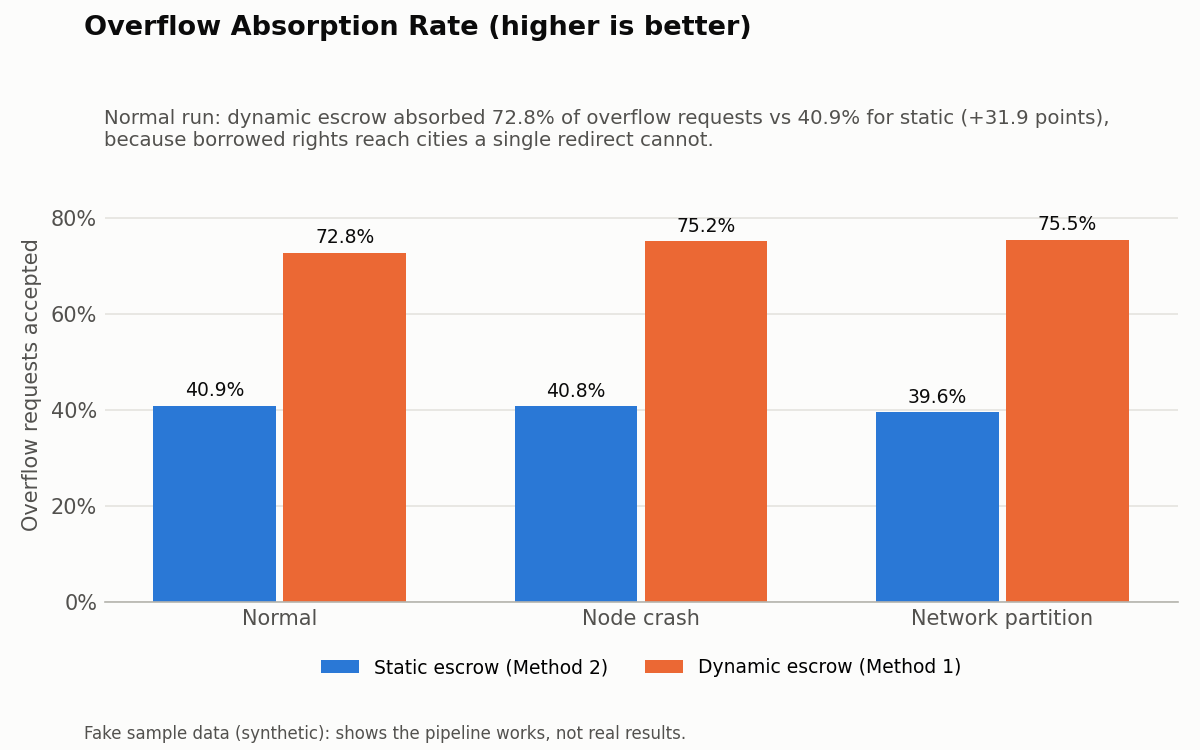

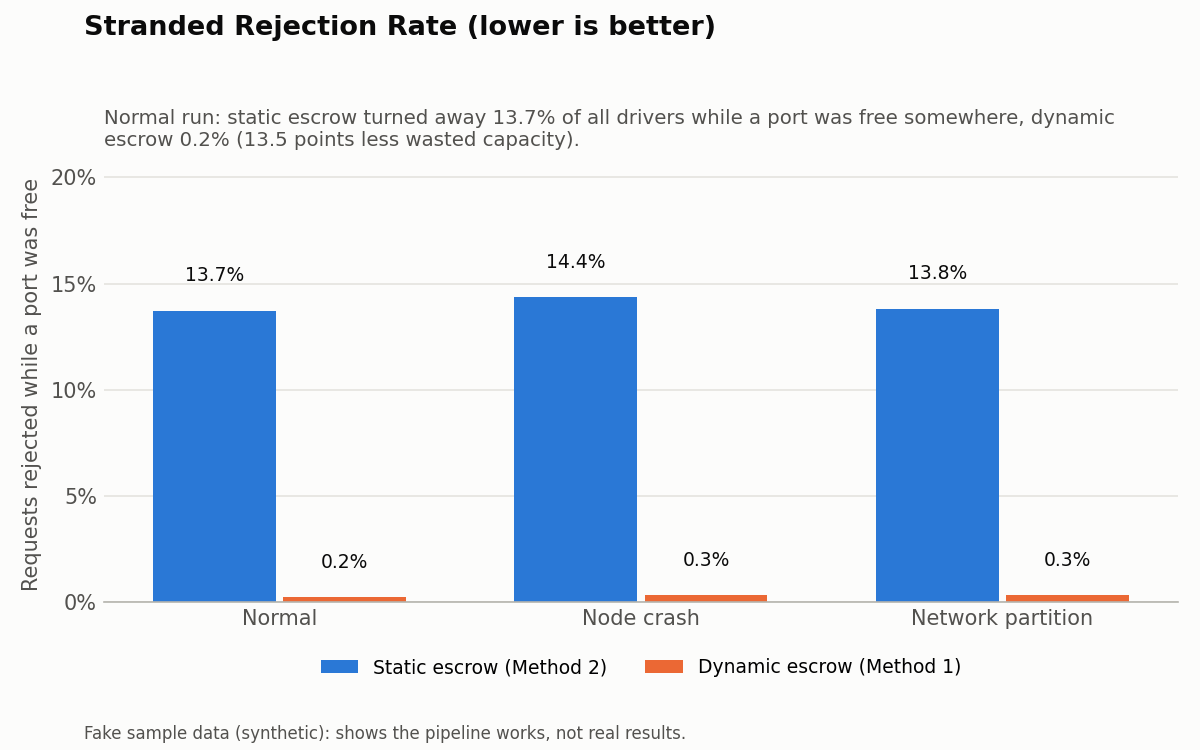

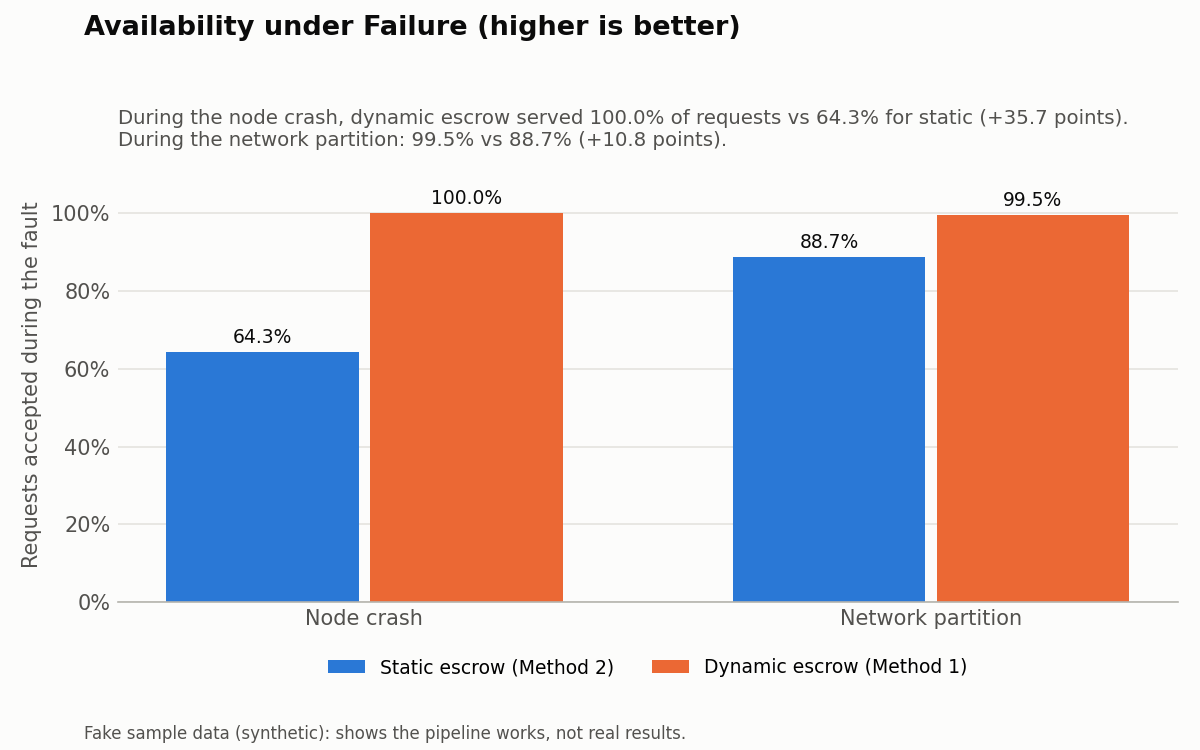

In [10]:
# Cell 10: one chart per metric, each with a takeaway sentence
synthetic = "synthetic" in df.columns and df["synthetic"].fillna(0).astype(int).eq(1).all()
foot = ("Fake sample data (synthetic): shows the pipeline works, not real results."
        if synthetic else f"Source: {os.path.basename(OUTCOMES)}")
t_oar = takeaway(s, "OAR", ["normal", "crash", "partition"])
t_srr = takeaway(s, "SRR", ["normal", "crash", "partition"], higher_is_better=False)
t_auf = takeaway(s, "AuF", ["crash", "partition", "transfer_crash"])
charts = [
    bar_chart(s, "OAR", SCENARIO_ORDER, "Overflow Absorption Rate (higher is better)",
              "Overflow requests accepted", os.path.join(OUT, "chart_OAR.png"), wrap(t_oar), foot),
    bar_chart(s, "SRR", SCENARIO_ORDER, "Stranded Rejection Rate (lower is better)",
              "Requests rejected while a port was free", os.path.join(OUT, "chart_SRR.png"), wrap(t_srr), foot),
    bar_chart(s, "AuF", ["crash", "partition", "transfer_crash"], "Availability under Failure (higher is better)",
              "Requests accepted during the fault", os.path.join(OUT, "chart_AuF.png"), wrap(t_auf), foot),
]
for c in charts:
    if c:
        display(Image(filename=c))

In [11]:
# Cell 11: takeaways and correctness verdict (also saved to summary.txt)
verdict = ("PASS - no double bookings and at most one booking city per port in every run."
           if (s["correctness"] == "PASS").all()
           else "FAIL - see double_booking_violations.csv / authority_violations.csv")
text = "\n".join(["EV Charging Port Management - evaluation summary", f"input: {OUTCOMES}", "",
                  show.to_string(index=False), "", "Takeaways", "  OAR: " + t_oar, "  SRR: " + t_srr,
                  "  AuF: " + t_auf, "", "Correctness: " + verdict])
open(os.path.join(OUT, "summary.txt"), "w").write(text + "\n")
print(text)
print("\nfiles in", OUT, ":", sorted(os.listdir(OUT)))

EV Charging Port Management - evaluation summary
input: /home/budayaku/ev_metrics/sample_data/outcomes.csv

 scenario  method  requests acceptance_rate  overflow_requests   OAR   SRR  fault_requests    AuF  lost_in_crash  D  authority_viol correctness
   normal  static      7838           86.3%               1820 40.9% 13.7%               0    n/a              0  0               0        PASS
   normal dynamic      7838           94.9%               1431 72.8%  0.2%               0    n/a              0  0               0        PASS
    crash  static      7838           85.6%               1827 40.8% 14.4%             406  64.3%             63  0               0        PASS
    crash dynamic      7838           94.9%               1548 75.2%  0.3%             406 100.0%             63  0               0        PASS
partition  static      7838           86.2%               1790 39.6% 13.8%             406  88.7%              0  0               0        PASS
partition dynamic      7838 